# thermals are ok
actually all along the thermals are fine! just some minor tweaks to them

In [1]:
import sys
import math
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset # !! new - building netcdf
import os # file saving 
import xarray as xr
from pathlib import Path
import importlib.util


In [2]:
save_loc_v3_2 = "./model_output_v3_2/" # location to save output files
save_name = 'new_thermal'
ncfile = xr.open_dataset(f"{save_loc_v3_2}{save_name}.nc", decode_times=False)
#ncfile_envi = xr.open_dataset(f"{save_loc_v3_2}{save_name}.nc", group="environment", engine="netcdf4",decode_times=False)
#ncfile_ice = xr.open_dataset(f"{save_loc_v3_2}{save_name}.nc", group="ice_particles", engine="netcdf4",decode_times=False)
#ncfile_splinter = xr.open_dataset(f"{save_loc_v3_2}{save_name}.nc", group="splinter_particles", engine="netcdf4",decode_times=False)

# also pull out the variables put into the namelist file
namelist_file = ncfile.attrs["namelist_file"]
with open(namelist_file, "r") as f:
    namelist_contents = f.read()
namelist = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist)

## pull out relevent functions
sys.path.append('/home/users/esree/simple-graupel-model/')
# i have moved all the smaller functions to a seperate file - so can be accessed when plotting too
from graupel_model_sub_functions import trev, ptz, find_grid_index, boundary_velocity, ztp

/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [28]:
diam = namelist['diam']
#numt = int(namelist['runtime'] * 60. / namelist['DELTIM']) ### number of simulation time steps (s)
numt = int(200 * 60. / namelist['DELTIM']) ### number of simulation time steps (s)
numt_0 = numt + 1 # including initial time step (t=0)
MAX1 = len(diam)   # number of particle size categories

thtop1 = np.zeros(numt_0)                          # top alt of thermal 1
thbase1 = np.zeros(numt_0)                         # bottom alt of thermal 1
thtop2 = np.zeros(numt_0)                          # top alt of thermal 2
thbase2 = np.zeros(numt_0)                         # bottom alt of thermal 2
cldtop = np.zeros(numt_0)                          # top of cloud top debis
downbase = np.zeros(numt_0)                        # bottom of cloud top debris
thermodynamic_flag = np.zeros(numt_0)              # flag to indicate if thermodynamic conditions in each section

# the whole environment is initialised with empty arrays defined by MAX values
lw = np.zeros(namelist['MAX2'])                              # LWC (at all heights)
db = np.zeros(namelist['MAX2'])                              # dbar ??
vv = np.zeros(namelist['MAX2'])                              # vertical velocity
alt = np.zeros(namelist['MAX2'])                             # altitude (m?)
ps = np.zeros(namelist['MAX2'])                              # pressure (mb?)
tr = np.zeros(namelist['MAX2'])                              # temperature (Kelvin)
conc = np.zeros(MAX1)                            # concentration of particles in each size category

# 2c. define cloud properties: pressure / temperature / depth /vertical velocity profile - - - - - - - - - - - - - - - - - - - - - - - - - - - -
zbase = ptz(namelist['pbase']) # height of cloud base (m)
#print(f"cloud base: p = {namelist['pbase']:5.1f} mb, T = {namelist['tbase']:4.1f} C, "f"z = {zbase / 1000.:3.1f} km", file=sys.stderr)
cdepth = namelist['CTOP'] - zbase / 1000. # depth of cloud (km)

# vertical velocity change with alt -> slope and intercept of (linear) vertical velocity profile
slope = (namelist['maxup'] - namelist['wbase']) / (namelist['zmax'] - zbase / 1000.)
intcpt = namelist['wbase'] - slope * zbase / 1000.

# 3. set up environmental profile
# build environment profile - - - - - - - - - - - - - - - - - - - - - - - - - - - -
for ii in range(namelist['MAX2']):
    # whole column properties
    alt[ii] = 10. * ii # each level seperated by 10 m
    ps[ii] = ztp(alt[ii]) # pressure
    at_, alwc_ = trev(namelist['pbase'], namelist['tbase'], ps[ii]) # temp + LWC
    lw[ii] = alwc_ * 1.0e-3 # lwc through column
    tr[ii] = at_ + 273.15 # temp through column
    db[ii] = namelist['DBAR'] + ii / 125. # mean cloud drop diameter (not sure why / 125.)

    # environmental updraft
    # vv = vertical velocity defined at each height
    if alt[ii] < zbase:
        # below cloud
        vv[ii] = 1.
    elif alt[ii] / 1000. <= namelist['zmax']:
        # in cloud + alt < max updraft alt
        # increasing updraft to zmax
        vv[ii] = slope * alt[ii] / 1000. + intcpt
    else:
        # in cloud + alt >= zmax
        # decreasing updraft above this
        vv[ii] = (namelist['maxup'] / ((namelist['CTOP'] + 2.) - namelist['zmax'])) * ((namelist['CTOP'] + 2.) - alt[ii] / 1000.0)


### set up of initial state of thermals

In [13]:
thtop1[0] = namelist['zinit'] / 1000. # top of thermal initally at the particles initial height

if thtop1[0] > namelist['CTOP']:
    thtop1[0] = namelist['CTOP'] # top of thermal cannot exceed cloud top
cldtop[0] = thtop1[0] # cloud top = thermal top
thbase1[0] = thtop1[0] - namelist['TDEPTH'] # base of thermal

if thbase1[0] < 0.:
    thbase1[0] = 0. # base of thermal cannot be below ground

# 4b. setting up second thermal - - - - - - - - - - - - - - - - - - - - - - - - - - - -
thtop2[0] = thbase1[0] - namelist['TGAP'] # set second thermal below first thermal by TGAP
if thtop2[0] < 0.:
    thtop2[0] = np.nan # top of second thermal cannot be below ground
thbase2[0] = thtop2[0] - namelist['TDEPTH']
if thbase2[0] < 0.:
    thbase2[0] = np.nan # base of second thermal cannot be below ground
downbase[0] = np.nan  # bottom of cloud top debris

post1 = posb1 = post2 = posb2 = 0 
post1 = find_grid_index(thtop1[0], alt)
posb1 = find_grid_index(thbase1[0], alt)
post2 = find_grid_index(thtop2[0], alt)
posb2 = find_grid_index(thbase2[0], alt)

wtht1 = boundary_velocity(post1, vv)
wthb1 = boundary_velocity(posb1, vv)
wtht2 = boundary_velocity(post2, vv)
wthb2 = boundary_velocity(posb2, vv)

### time step of following thermals through time

In [14]:
topflag = tht2flag = thb2flag = 0
# loop through each time step
for i in range(1, numt_0):
    # move thermal 1 * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
    # deal with thermal 1 top
    thtop1[i] = thtop1[i - 1] + (wtht1 * namelist['DELTIM']) / 1000. # new height = old height + velocity × time
    if thtop1[i] >= namelist['CTOP']:
        thtop1[i] = namelist['CTOP']

    # deal with thermal 1 base
    thbase1[i] = thtop1[i] - namelist['TDEPTH']
    if thbase1[i] > 0.:
        # base of thermal 1 is above ground, so it does exist
        thbase1[i] = thbase1[i - 1] + (wthb1 * namelist['DELTIM']) / 1000.
    if thbase1[i] < 0.:
        thbase1[i] = 0. # base of thermal cannot be below ground

    # create / move thermal 2 * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
    if tht2flag != 1:
        # if thermal top 2 has not been initilised 
        thtop2[i] = thbase1[i] - namelist['TGAP']
        if thtop2[i] > 0.: # if thermal top 2 is above ground, then initialise it
            tht2flag = 1
        if thtop2[i] < 0.: # if thermal top 2 is below ground, np.nan it
            thtop2[i] = np.nan
    else:
        # if thermal top 2 has been initialised, then move it
        thtop2[i] = thtop2[i - 1] + (wtht2 * namelist['DELTIM']) / 1000.

    if thb2flag != 1:
        # if thermal base 2 has not been initilised
        thbase2[i] = thtop2[i] - namelist['TDEPTH'] # initalise thermal 2 base
        if thbase2[i] > 0.:
            thb2flag = 1
        if thbase2[i] < 0.: # if thermal base 2 is below ground, np.nan it
            thbase2[i] = np.nan
    else:
        # thermal 2 base above ground, so it does exist
        thbase2[i] = thbase2[i - 1] + (wthb2 * namelist['DELTIM']) / 1000.

    # deal with cloud top region * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
    if thtop1[i] >= namelist['CTOP'] and thbase1[i] >= (namelist['CTOP'] - namelist['TDEPTH'] / 4.) and topflag == 0:
        # thermal is approaching maximum cloud top -> stopping growth 
        topflag = 1 # switch on processes -> thermal at top is decaying
        thtop1[i] = thtop2[i]
        thbase1[i] = thbase2[i]
        thtop2[i] = thbase1[i] - namelist['TGAP']
        thbase2[i] = thtop2[i] - namelist['TDEPTH']
        tht2flag = thb2flag = 0 
        cldtop[i - 1] = namelist['CTOP'] # new?
        # now this condition has been reached, thermal 1 is decaying.

    if topflag == 1:
        # thermal has reached cloud top -> thermal stopped growing, now become region of descending material 
        cldtop[i] = cldtop[i - 1] + (namelist['WCTDEB'] * namelist['DELTIM']) / 1000. # cloud top region grows
        # if this included - the cloud top does not decend as much in decaying phase
        #if cldtop[i] <= namelist['GENCTOP']:
        #    cldtop[i] = namelist['GENCTOP']
        
        downbase[i] = cldtop[i] - namelist['TDEPTH'] / 4. # base of cloud top region - this is where the bottom of thermal 1 is 
        if downbase[i] <= thtop1[i]:
            downbase[i] = thtop1[i]
        if cldtop[i] < thtop1[i]:
            topflag = 0
    else:
        # thermal is not near max cloud top -> still growing
        cldtop[i] = thtop1[i]
        downbase[i] = np.nan

    # again find environmental grid location of the thermals * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
    post1 = posb1 = post2 = posb2 = 0
    post1 = find_grid_index(thtop1[i], alt)
    posb1 = find_grid_index(thbase1[i], alt)
    post2 = find_grid_index(thtop2[i], alt)
    posb2 = find_grid_index(thbase2[i], alt)

    wtht1 = boundary_velocity(post1, vv)
    wthb1 = boundary_velocity(posb1, vv)
    wtht2 = boundary_velocity(post2, vv)
    wthb2 = boundary_velocity(posb2, vv)

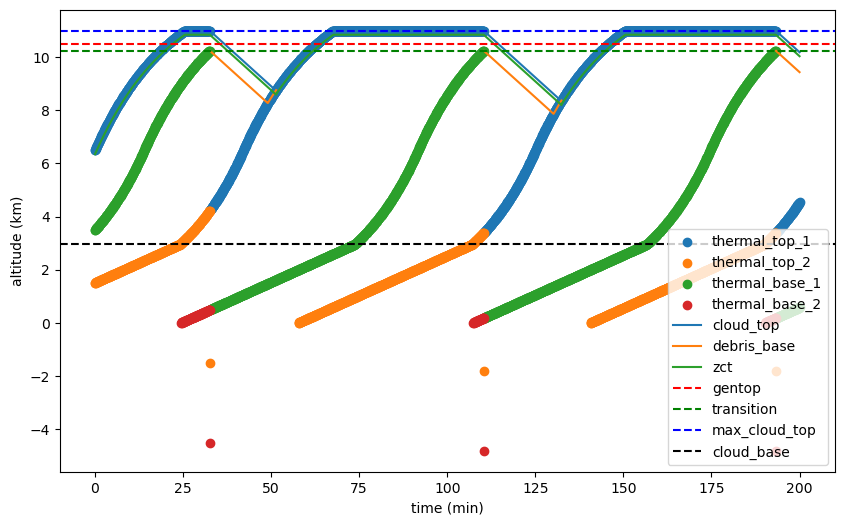

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))
time = np.arange(0, len(thtop1)) * namelist['DELTIM'] / 60

plt.scatter(time, thtop1, label='thermal_top_1')
plt.scatter(time, thtop2, label='thermal_top_2')
plt.scatter(time, thbase1, label='thermal_base_1')
plt.scatter(time, thbase2, label='thermal_base_2')

plt.plot(time, cldtop, label='cloud_top')
plt.plot(time, downbase, label='debris_base')
zbase = ptz(namelist['pbase']) # height of cloud base (m)
thbase_transition = namelist['CTOP'] - namelist['TDEPTH'] / 4.
GENCTOP = namelist['GENCTOP'] # height of cloud top (m)
CTOP = namelist['CTOP'] # height of cloud top (m)
ZCT = namelist['ZCT'] # height of cloud top (m)
ZCT_values = [v - ZCT for v in cldtop]
plt.plot(time, ZCT_values, label='zct')
plt.axhline(y=GENCTOP, color='r', linestyle='--', label='gentop')
plt.axhline(y=thbase_transition, color='g', linestyle='--', label='transition')
plt.axhline(y=CTOP, color='b', linestyle='--', label='max_cloud_top')
plt.axhline(y=zbase/1000, color='k', linestyle='--', label='cloud_base')

plt.ylabel("altitude (km)")
plt.xlabel("time (min)")
plt.legend()
#plt.ylim(0, 12)

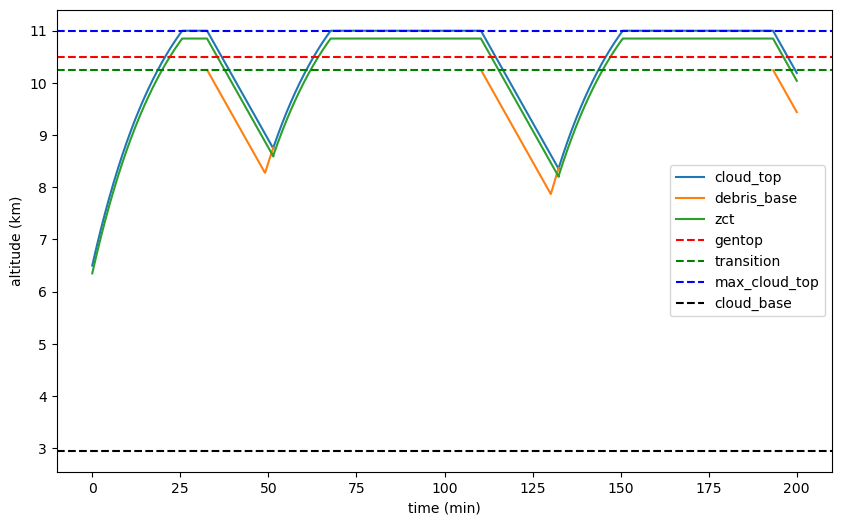

In [27]:
fig, ax = plt.subplots(figsize=(10, 6))
time = np.arange(0, len(thtop1)) * namelist['DELTIM'] / 60
'''
plt.scatter(time, thtop1, label='thermal_top_1')
plt.scatter(time, thtop2, label='thermal_top_2')
plt.scatter(time, thbase1, label='thermal_base_1')
plt.scatter(time, thbase2, label='thermal_base_2')
'''
plt.plot(time, cldtop, label='cloud_top')
plt.plot(time, downbase, label='debris_base')
zbase = ptz(namelist['pbase']) # height of cloud base (m)
thbase_transition = namelist['CTOP'] - namelist['TDEPTH'] / 4.
GENCTOP = namelist['GENCTOP'] # height of cloud top (m)
CTOP = namelist['CTOP'] # height of cloud top (m)
ZCT = namelist['ZCT'] # height of cloud top (m)
ZCT_values = [v - ZCT for v in cldtop]
plt.plot(time, ZCT_values, label='zct')
plt.axhline(y=GENCTOP, color='r', linestyle='--', label='gentop')
plt.axhline(y=thbase_transition, color='g', linestyle='--', label='transition')
plt.axhline(y=CTOP, color='b', linestyle='--', label='max_cloud_top')
plt.axhline(y=zbase/1000, color='k', linestyle='--', label='cloud_base')

plt.ylabel("altitude (km)")
plt.xlabel("time (min)")
plt.legend()
#plt.ylim(0, 12)

* drop off in thermaltop1 

In [ ]:
## the code for dealing where the particles are wrt the thermals

# 2. where is the particle with respect to the thermal? * * * * * * * * * * * * * * * * * * * * * * * * * *
# this modifies the environmental conditions -> alter particle growth and movement
hw = 0 # horizontal wind (m/s) # not persistent between time steps
if downflag == 0: # particle is not in downdraft
    ## *** particle is in thermal *** - condition 1 
    if ((zkm <= thtop1[i] - namelist['ZCT'] and zkm >= thbase1[i]) or (zkm <= thtop2[i] - namelist['ZCT'] and zkm >= thbase2[i])):
        # particle is still in thermal (can be thermal 1 or thermal 2)
        temp = tr[pos] - 1. # thermal envi is 1ºC cooler than the environment
        lwc = namelist['RATTH'] * lw[pos]
        dbar = db[pos] # drop size
        wi = vv[pos] # vertical velocity - based on the vertical velocity profile of the thermal

    ## *** particle is in ZCT zone (only region where it can move horizontally) *** condition 2
    # in very top of the cloud -> horizontal wind kicks in -> move particle into downdraft
    if zkm <= thtop1[i] and zkm >= thtop1[i] - namelist['ZCT']:
        temp = tr[pos] - 1.
        lwc = namelist['RATCT'] * lw[pos]
        dbar = db[pos]
        hw = umax
        # work out smooth vertical velocity in cloud top regions
        wi = vv[pos] - vv[pos] * (zkm - (thtop1[i] - namelist['ZCT'])) / (2. * namelist['ZCT']) # vertical velocity change with height

    # out of thermal -> in debris under thermal // above thermal (if at start) *** condition 3 - debris 
    if ((zkm > thtop1[i] or zkm < thbase1[i]) and (zkm > thtop2[i] or zkm < thbase2[i]) and (zkm < downbase[i])) or (zkm > thtop1[i] and zkm > thtop2[i]):
        temp = tr[pos] - 1.
        lwc = namelist['RATDEB'] * lw[pos]
        dbar = db[pos]
        hw = 0.
        wi = 0.0 # this applies if outside cloud

    # above thermal 1, within cloud top, in descending thermal remnants *** condition 4 -- a and b
    if zkm > thtop1[i] and zkm <= cldtop[i] and zkm >= downbase[i]:
        temp = tr[pos] - 2.
        lwc = namelist['RATDEB'] * lw[pos]
        dbar = db[pos]
        hw = 0.
        if cldtop[i] > namelist['GENCTOP']:
            #*** condition 4a
            # cloud top above general cloud top -> prescribed verical velocity
            wi = namelist['WCTDEB']
        else:
            ## condition 4b
            wi = 0.

    # horizontal position in km **** condition 5
    if x >= namelist['TWID']:
        # particle has left the thermal, into downdraught
        temp = tr[pos] - 2.
        lwc = namelist['RATDOWN'] * lw[pos]
        dbar = db[pos]
        hw = 0.
        wi = -5.
        downflag = 1 # in downdraft
        zdown = zkm

else:
    # particle is in downdraft **** condition 6
    temp = tr[pos] - 2.
    lwc = namelist['RATDOWN'] * lw[pos]
    dbar = db[pos]
    hw = 0.
    wi = -5.
    # make downdraughts no deeper than DDEPTH km
    if abs(zdown - zkm) >= namelist['DDEPTH']:
        # reset particle to normal environment
        downflag = 0
        xold = 0
        x = 0.
        zdown = 0.

# overshoot cloud top?
if zkm >= namelist['CTOP'] or zkm > cldtop[i]:
    zkm = cldtop[i] # adjust so don't overshoot top 

# deplete the lwc if above 7 km (due to conversion to ice)
if zkm >= 7:
    if zflag == 0:
        lwc7 = lwc
        zflag = 1
    if zflag > 0:
        lwc = lwc7 - (zkm - 7.) * lwc7 / (10. - 7.)
    if zkm >= 10.:
        lwc = 0.